# Phase 2 — Model Training & Nested CV Comparison

This notebook runs `ml/src/train.py`, displays the nested 5x10 Repeated Stratified CV comparison table, and shows the saved comparison & confusion-matrix figures.

In [1]:
import json
import sys
from pathlib import Path
from IPython.display import Image, display
import pandas as pd

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "shared").exists():
    PROJECT_ROOT = PROJECT_ROOT.parents[1]
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from ml.src.train import main as run_training

run_training()

Loaded 68 rows, 27 features.
Target distribution: {0: 11, 1: 30, 2: 27} (0=Low, 1=Medium, 2=High)
Evaluating Dummy (Majority)...


Evaluating Logistic Regression...


Evaluating Random Forest...


Evaluating XGBoost...



MODEL COMPARISON (Nested CV: outer 5x10 RepeatedStratifiedKFold, inner 3-fold GridSearchCV)
Model                 | CV Acc (mean±std) | CV F1 (mean±std)  | Train F1 | Gap    | ROC-AUC | F1 Low/Med/High
-------------------------------------------------------------------------------------------------------------
Dummy (Majority)      | 0.442 +/- 0.016   | 0.204 +/- 0.005   | 0.204    | -0.000 | 0.500   | 0.00 / 0.61 / 0.00
Logistic Regression   | 0.592 +/- 0.099   | 0.567 +/- 0.123   | 0.916    | +0.349 | 0.763   | 0.51 / 0.56 / 0.67
Random Forest         | 0.717 +/- 0.103   | 0.691 +/- 0.112   | 0.922    | +0.231 | 0.871   | 0.62 / 0.72 / 0.76
XGBoost               | 0.646 +/- 0.130   | 0.599 +/- 0.156   | 0.988    | +0.389 | 0.805   | 0.49 / 0.65 / 0.71

Chosen model: Random Forest
Reason: Highest nested CV macro-F1 (0.691 +/- 0.112). Note: within 1 SD of XGBoost (0.599 +/- 0.156), and Random Forest is tree-based so it pairs directly with SHAP TreeExplainer.
Honest check on Low class 

Permutation test: observed macro-F1 = 0.665, chance mean = 0.304 +/- 0.066, p-value = 0.0099



Saved plots to C:\Users\sriva\OneDrive\Desktop\Web Development\Projects\workplace-stress-predictor\artifacts\figures\09_model_comparison.png and C:\Users\sriva\OneDrive\Desktop\Web Development\Projects\workplace-stress-predictor\artifacts\figures\10_best_model_confusion_matrix.png


Saved final pipeline (fitted on all 68 rows) to C:\Users\sriva\OneDrive\Desktop\Web Development\Projects\workplace-stress-predictor\artifacts\stress_pipeline.joblib
Final best hyperparameters: {'clf__max_depth': 3, 'clf__min_samples_leaf': 2, 'clf__n_estimators': 150}
Saved metrics to C:\Users\sriva\OneDrive\Desktop\Web Development\Projects\workplace-stress-predictor\artifacts\metrics.json

Phase 2 training complete ✓


In [2]:
metrics_path = PROJECT_ROOT / "artifacts" / "metrics.json"
with open(metrics_path, encoding="utf-8") as f:
    metrics = json.load(f)

rows = []
for m in metrics["models"]:
    rows.append({
        "Model": m["name"],
        "CV Acc": f"{m['cv_accuracy_mean']:.3f} ± {m['cv_accuracy_std']:.3f}",
        "CV Macro-F1": f"{m['cv_macro_f1_mean']:.3f} ± {m['cv_macro_f1_std']:.3f}",
        "Train Macro-F1": round(m["train_macro_f1_mean"], 3),
        "Train-CV Gap": round(m["train_cv_gap"], 3),
        "ROC-AUC (OvR)": round(m["roc_auc_ovr_mean"], 3),
        "F1 Low": round(m["per_class_f1"]["Low"], 3),
        "F1 Medium": round(m["per_class_f1"]["Medium"], 3),
        "F1 High": round(m["per_class_f1"]["High"], 3),
    })
display(pd.DataFrame(rows))
print("Chosen model:", metrics["chosen_model_name"])
print("Reason:", metrics["selection_reason"])
print("Permutation test:", metrics["permutation_test"])

,Model,CV Acc,CV Macro-F1,Train Macro-F1,Train-CV Gap,ROC-AUC (OvR),F1 Low,F1 Medium,F1 High
0,Dummy (Majority),0.442 ± 0.016,0.204 ± 0.005,0.204,-0.000,0.500,0.000,0.612,0.000
1,Logistic Regression,0.592 ± 0.099,0.567 ± 0.123,0.916,0.349,0.763,0.512,0.558,0.668
2,Random Forest,0.717 ± 0.103,0.691 ± 0.112,0.922,0.231,0.871,0.617,0.720,0.764
3,XGBoost,0.646 ± 0.130,0.599 ± 0.156,0.988,0.389,0.805,0.493,0.649,0.705


Chosen model: Random Forest
Reason: Highest nested CV macro-F1 (0.691 +/- 0.112). Note: within 1 SD of XGBoost (0.599 +/- 0.156), and Random Forest is tree-based so it pairs directly with SHAP TreeExplainer.
Permutation test: {'observed_macro_f1': 0.665058645058645, 'perm_mean_macro_f1': 0.3040473103894157, 'perm_std_macro_f1': 0.065752580962366, 'p_value': 0.009900990099009901, 'n_permutations': 100}


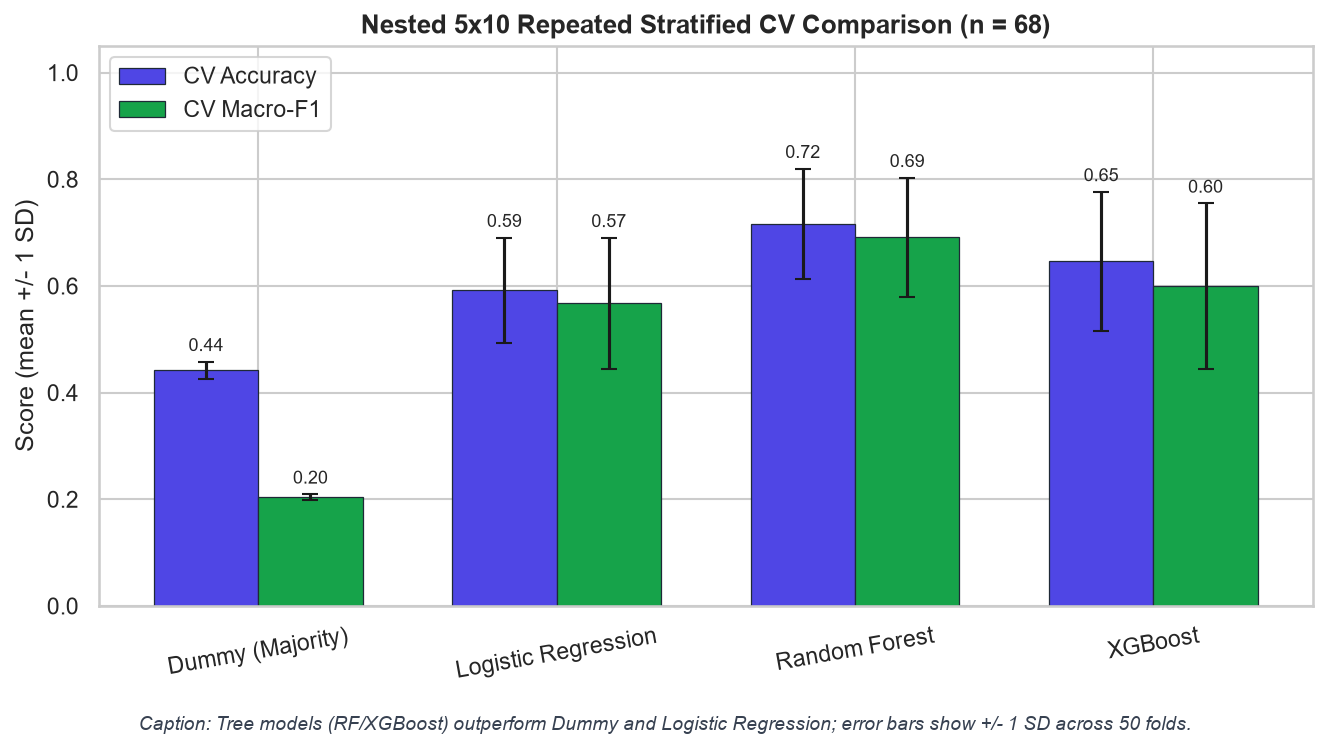

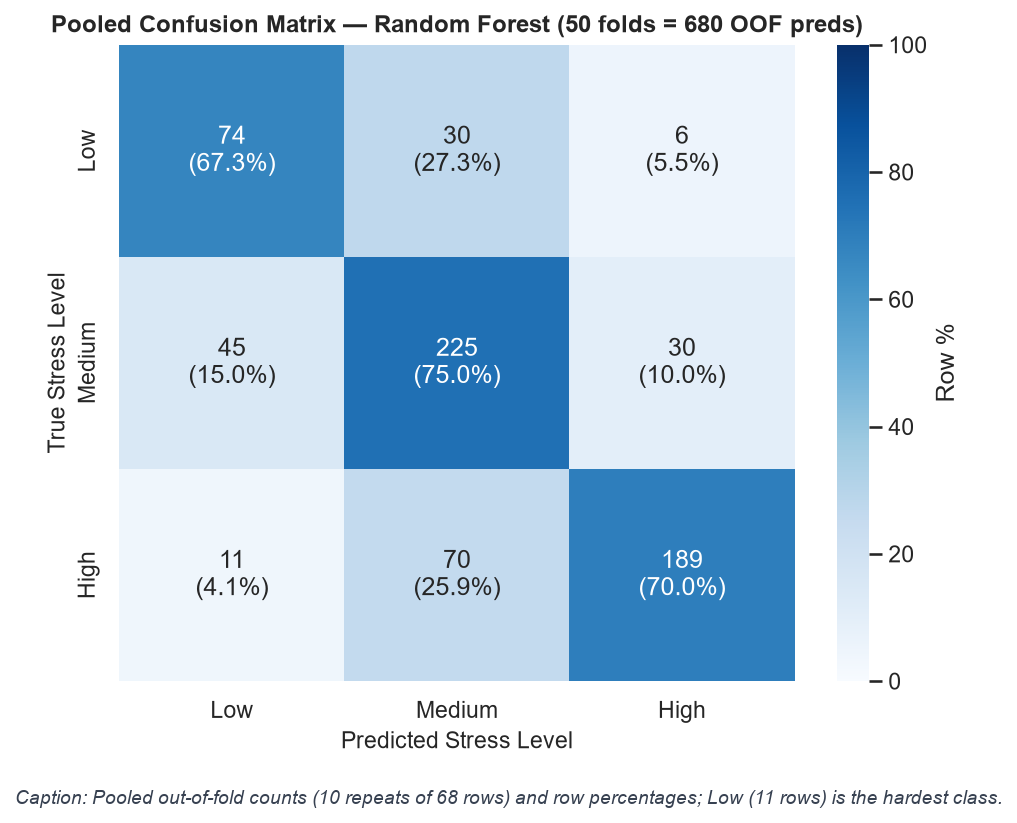

In [3]:
display(Image(filename=str(PROJECT_ROOT / "artifacts" / "figures" / "09_model_comparison.png")))
display(Image(filename=str(PROJECT_ROOT / "artifacts" / "figures" / "10_best_model_confusion_matrix.png")))